# Stage 5 — Data efficiency and noise robustness

**Vamsi Gudipati**

Two questions across the earlier stages, three seeds each. **A.** How much data does the Darcy DeepONet of Stage 4 need? I train it on 10 %, 25 %, 50 % and 100 % of its 1,500 training functions (a different random subset per seed), 200 epochs each, and score it on the same 80 held-out fields. **B.** How robust are the two inverse solvers to noisy observations? I add Gaussian noise of 0, 1, 5 and 10 % of the signal's standard deviation to the observations of the DeepXDE conductivity problem of Stage 2 and of the hand-written λ problem of Stage 3, and report the recovered parameter and its error against the true value side by side. The code blocks are copied from the earlier stages and every model is trained again here; nothing is read from their outputs. Everything runs on the CPU.

Portfolio page: https://vamsigudipati.github.io/physics-informed-pinn-deeponet.html


In [1]:
# Where this notebook writes its outputs (paths relative to notebooks/)
from pathlib import Path
STAGE = "05_data_efficiency_and_noise"
RESULTS_DIR = Path("../results") / STAGE
EXERCISES_DIR = RESULTS_DIR / "exercises"
MODELS_DIR = Path("../models") / STAGE
ANIM_DIR = Path("../animations")
ANIM_PREFIX = "05_"
for _d in (RESULTS_DIR, EXERCISES_DIR, MODELS_DIR, ANIM_DIR):
    _d.mkdir(parents=True, exist_ok=True)

In [2]:
import os, time, pickle
os.environ["DDE_BACKEND"] = "pytorch"
import numpy as np, pandas as pd, torch, torch.nn as nn, matplotlib.pyplot as plt
from pathlib import Path
RES = RESULTS_DIR; RES.mkdir(exist_ok=True); MODELS = MODELS_DIR; MODELS.mkdir(exist_ok=True)
SEEDS = (0, 1, 2)
torch.set_num_threads(2)                      # as in Stage 4
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
CB = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442"]
print("torch", torch.__version__)

torch 2.14.1


## A. DeepONet data efficiency
The solver, the permeability generator, the dataset builder, the model and the training function are copied from Stage 4 (the training function without its animation hook). The 1,500 training fields and the 80 validation fields are built exactly as there (`default_rng(1)`, training set first), so the test set is Stage 4's validation set. For each fraction and seed I draw a random subset of the training fields with `default_rng(1000 + seed)`; the target scale is the maximum pressure of that subset, as Stage 4 scales by the maximum of its training set.

In [3]:
# from Stage 4: 2D finite-volume Darcy solver on the unit square, u = 0 on the boundary.
def darcy_solve(a, f=1.0):
    N = a.shape[0]; h = 1.0/(N-1)
    inner = [(r, c) for r in range(1, N-1) for c in range(1, N-1)]
    pos = {rc: k for k, rc in enumerate(inner)}
    A = np.zeros((len(inner),)*2); b = np.zeros(len(inner))
    harm = lambda p, q: 2*p*q/(p+q)
    for (r, c) in inner:
        k = pos[(r, c)]; b[k] = f*h*h; diag = 0
        for dr, dc in [(-1,0),(1,0),(0,-1),(0,1)]:
            rr, cc = r+dr, c+dc
            tw = harm(a[r, c], a[rr, cc]); diag += tw
            if (rr, cc) in pos:
                A[k, pos[(rr, cc)]] -= tw
        A[k, k] = diag
    u = np.zeros((N, N)); sol = np.linalg.solve(A, b)
    for (r, c), k in pos.items():
        u[r, c] = sol[k]
    return u

# from Stage 4: blocky two-material permeability.
def random_perm(N, rng, hi=12.0, lo=3.0):
    nb = rng.integers(2, 5)
    cg = rng.random((nb, nb)) < rng.uniform(0.3, 0.7)
    a = np.kron(cg, np.ones((int(np.ceil(N/nb)),)*2))[:N, :N]
    return np.where(a, hi, lo)

# from Stage 4: a small MLP with GELU activations and Xavier init.
def mlp(d_in, width, depth, d_out, act=nn.GELU):
    layers = [nn.Linear(d_in, width), act()]
    for _ in range(depth-1):
        layers += [nn.Linear(width, width), act()]
    layers += [nn.Linear(width, d_out)]
    net = nn.Sequential(*layers)
    for m in net:
        if isinstance(m, nn.Linear):
            nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)
    return net

# from Stage 4: the DeepONet.
class DeepONet(nn.Module):
    def __init__(self, m_sensors, p=128, width=128, depth=3):
        super().__init__()
        self.branch = mlp(m_sensors, width, depth, p)
        self.trunk  = mlp(2,         width, depth, p)
        self.b0 = nn.Parameter(torch.zeros(1))
    def forward(self, a, y):
        B = self.branch(a); T = self.trunk(y)
        return B @ T.T + self.b0

# from Stage 4: dataset of (permeability, pressure) pairs.
def build_dataset(N, n, rng, hi=12.0, lo=3.0):
    xs = np.linspace(0, 1, N); XX, YY = np.meshgrid(xs, xs)
    coords = np.stack([XX.ravel(), YY.ravel()], -1).astype(np.float32)
    A = np.zeros((n, N*N), np.float32); U = np.zeros((n, N*N), np.float32)
    araw = np.zeros((n, N, N), np.float32)
    for i in range(n):
        a = random_perm(N, rng, hi, lo); u = darcy_solve(a)
        A[i] = ((a - lo)/(hi - lo)).ravel()
        U[i] = u.ravel(); araw[i] = a
    return coords, A, U, araw

# from Stage 4: relative L2 error.
def rel_l2(pred, target):
    return (torch.norm(pred - target) / torch.norm(target)).item()

# from Stage 4: Adam with a cosine-decayed learning rate.
def train_deeponet(model, At, Ut, C, epochs=200, bs=32, lr=2e-3, seed=0, log_every=40):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    lossf = nn.MSELoss(); hist = []
    for ep in range(1, epochs+1):
        model.train()
        perm = torch.randperm(len(At)); tot = 0.0; nb = 0
        for i in range(0, len(At), bs):
            b = perm[i:i+bs]; opt.zero_grad()
            loss = lossf(model(At[b], C), Ut[b])
            loss.backward(); opt.step()
            tot += loss.item(); nb += 1
        sched.step(); hist.append(tot/nb)
        if ep % log_every == 0 or ep == 1:
            print(f"  epoch {ep:3d} | train MSE {hist[-1]:.2e}")
    return hist

# from Stage 4: the notebook's training and validation sets (the validation set is the test set here).
N = 10; NTRAIN, NVAL = 1500, 80
rng = np.random.default_rng(1)
coords, Atr, Utr, Araw_tr = build_dataset(N, NTRAIN, rng)
coords_v, Ava, Uva, Araw_va = build_dataset(N, NVAL, rng)
C = torch.tensor(coords); Avt = torch.tensor(Ava)
print("training fields:", Atr.shape[0], "| test fields:", Ava.shape[0], "| sensors/field:", Atr.shape[1])

training fields: 1500 | test fields: 80 | sensors/field: 100


  epoch   1 | train MSE 6.09e-02


  10 % ( 150 fields), seed 0: test relative L2 0.3042 (1 s)
  epoch   1 | train MSE 5.63e-02


  10 % ( 150 fields), seed 1: test relative L2 0.3044 (1 s)
  epoch   1 | train MSE 6.07e-02


  10 % ( 150 fields), seed 2: test relative L2 0.3046 (1 s)
  epoch   1 | train MSE 4.89e-02


  25 % ( 375 fields), seed 0: test relative L2 0.2263 (2 s)
  epoch   1 | train MSE 5.00e-02


...

  50 % ( 750 fields), seed 1: test relative L2 0.0869 (4 s)
  epoch   1 | train MSE 5.09e-02


  50 % ( 750 fields), seed 2: test relative L2 0.0813 (4 s)
  epoch   1 | train MSE 4.17e-02


 100 % (1500 fields), seed 0: test relative L2 0.0577 (8 s)
  epoch   1 | train MSE 4.02e-02


 100 % (1500 fields), seed 1: test relative L2 0.0711 (8 s)
  epoch   1 | train MSE 4.23e-02


 100 % (1500 fields), seed 2: test relative L2 0.0628 (8 s)
 fraction  n_train   mean    std    min    max
     0.10      150 0.3044 0.0002 0.3042 0.3046
     0.25      375 0.2270 0.0124 0.2149 0.2397
     0.50      750 0.0882 0.0076 0.0813 0.0964
     1.00     1500 0.0639 0.0068 0.0577 0.0711


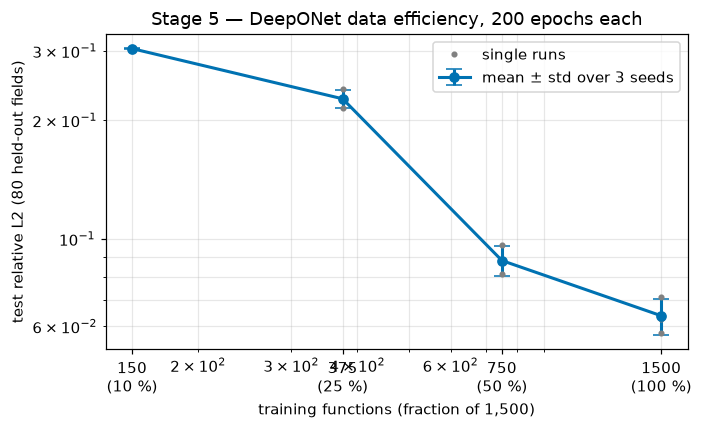

Result (A): test relative L2 150 fields: 0.3044 ± 0.0002; 375 fields: 0.2270 ± 0.0124; 750 fields: 0.0882 ± 0.0076; 1500 fields: 0.0639 ± 0.0068


In [4]:
FRACS = (0.10, 0.25, 0.50, 1.00); EPOCHS = 200
rows_a = []
for frac in FRACS:
    n_sub = int(round(frac * NTRAIN))
    for s in SEEDS:
        idx = np.sort(np.random.default_rng(1000 + s).choice(NTRAIN, n_sub, replace=False))
        A_s, U_s = Atr[idx], Utr[idx]; us = float(U_s.max())
        m = DeepONet(m_sensors=N*N, p=128, width=128, depth=3); t0 = time.time()
        h = train_deeponet(m, torch.tensor(A_s), torch.tensor(U_s / us), C, epochs=EPOCHS, bs=32, lr=2e-3, seed=s, log_every=10**9); tt = time.time() - t0
        m.eval()
        with torch.no_grad(): err = rel_l2(m(Avt, C), torch.tensor(Uva / us))
        torch.save(m.state_dict(), MODELS / f"deeponet_frac{int(frac*100):03d}_seed{s}.pth")
        rows_a.append(dict(fraction=frac, n_train=n_sub, seed=s, test_rel_l2=err, final_train_mse=h[-1], uscale=us, train_s=round(tt, 1)))
        print(f"{frac*100:4.0f} % ({n_sub:4d} fields), seed {s}: test relative L2 {err:.4f} ({tt:.0f} s)")
runs_a = pd.DataFrame(rows_a); runs_a.to_csv(RES / "a_data_efficiency_runs.csv", index=False)
summ_a = runs_a.groupby(["fraction", "n_train"])["test_rel_l2"].agg(["mean", "std", "min", "max"]).reset_index(); summ_a.to_csv(RES / "a_data_efficiency_summary.csv", index=False)
print(summ_a.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.errorbar(summ_a.n_train, summ_a["mean"], yerr=summ_a["std"], fmt="o-", color=CB[0], capsize=5, lw=2, label="mean ± std over 3 seeds")
for s in SEEDS:
    r = runs_a[runs_a.seed == s]; ax.plot(r.n_train, r.test_rel_l2, ".", color="0.5", ms=6, label="single runs" if s == 0 else None)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(summ_a.n_train); ax.set_xticklabels([f"{n}\n({f*100:.0f} %)" for n, f in zip(summ_a.n_train, summ_a.fraction)])
ax.set_xlabel("training functions (fraction of 1,500)"); ax.set_ylabel("test relative L2 (80 held-out fields)"); ax.grid(alpha=0.3, which="both"); ax.legend()
ax.set_title("Stage 5 — DeepONet data efficiency, 200 epochs each"); plt.tight_layout(); plt.savefig(RES / "a_data_efficiency.png", dpi=110); plt.show()
print("Result (A): test relative L2 " + "; ".join(f"{int(r.n_train)} fields: {r['mean']:.4f} ± {r['std']:.4f}" for _, r in summ_a.iterrows()))

## B. Inverse-problem robustness to noise
**DeepXDE.** The finite-difference reference, the bilinear sampler, the 12 sensors and `inverse_k` are copied from Stage 2, with its full recipe: start at k = 1.5, Adam for 3,000 iterations, then L-BFGS (at most 1,000 iterations). The noise is zero-mean Gaussian with a standard deviation equal to the given fraction of the standard deviation of the 12 clean readings, drawn with `default_rng(200 + seed)`; the seed also sets DeepXDE's own seed. Stage 2's own noise study scales the noise by the field maximum and uses Adam only; this one scales by the signal spread and uses the full recipe.

**By hand.** The training loop of Stage 3 (a 1–16–1 tanh network, λ starting at 1, Adam at 2e-3, 10,000 iterations, loss = physics residual + data mismatch) wrapped in a function. Its four observations are sin(2x) at x = 0.5, 1, 1.5, 2; the noise standard deviation is the given fraction of the standard deviation of those four clean values, drawn with the same seeds, and `torch.manual_seed(seed)` sets the network.

In [5]:
# from Stage 2: the PyTorch backend must be chosen before importing deepxde.
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import deepxde as dde
torch.set_default_device("cpu")         # DeepXDE 1.15 makes the Apple GPU (MPS) the default device on import; it is slower here (4.4 vs 1.9 ms per Adam iteration), so I keep the CPU
print("deepxde", dde.__version__, "| backend", dde.backend.backend_name)
# from Stage 2: seed and L-BFGS guardrail.
dde.config.set_random_seed(0); np.random.seed(0)
dde.optimizers.set_LBFGS_options(maxiter=1000)
# from Stage 2: read a trainable variable; record it after each epoch.
def read_var(v):
    return float(v.item())
class TrackVar(dde.callbacks.Callback):
    def __init__(self, var):
        super().__init__(); self.var = var; self.history = []
    def on_epoch_end(self):
        self.history.append(read_var(self.var))
# from Stage 2: finite-difference reference for -k(T_xx + T_yy) = Q, T = 0 on the edges.
def fd_poisson(k, Q, n=61):
    h = 1.0 / (n - 1); Nn = n - 2
    e = np.ones(Nn)
    T1 = sp.diags([e[:-1], -2 * e, e[:-1]], [-1, 0, 1]); I = sp.identity(Nn)
    L = (sp.kron(I, T1) + sp.kron(T1, I)) / h**2
    b = np.full(Nn * Nn, -Q / k); u = spla.spsolve(L.tocsr(), b)
    T = np.zeros((n, n)); T[1:-1, 1:-1] = u.reshape(Nn, Nn)
    return T
# from Stage 2: ground truth.
k_true, Q = 0.8, 1.0; n_ref = 61
T_ref = fd_poisson(k_true, Q, n=n_ref)
# from Stage 2: the geometry.
geom = dde.geometry.Rectangle([0, 0], [1, 1])
# from Stage 2: bilinear sampler.
def sample_field(T, xq, yq):
    n = T.shape[0]
    gx = np.clip(xq * (n - 1), 0, n - 1 - 1e-9); gy = np.clip(yq * (n - 1), 0, n - 1 - 1e-9)
    x0 = np.floor(gx).astype(int); fx = gx - x0; y0 = np.floor(gy).astype(int); fy = gy - y0
    bottom = T[y0, x0] * (1 - fx) + T[y0, x0 + 1] * fx
    top    = T[y0 + 1, x0] * (1 - fx) + T[y0 + 1, x0 + 1] * fx
    return bottom * (1 - fy) + top * fy
# from Stage 2: the 12 sensors.
rng_s = np.random.default_rng(1); N_sensors = 12
sx = rng_s.uniform(0.1, 0.9, N_sensors); sy = rng_s.uniform(0.1, 0.9, N_sensors)
obs_xy = np.column_stack([sx, sy]); obs_T = sample_field(T_ref, sx, sy).reshape(-1, 1)
# from Stage 2: the inverse solve for k.
def inverse_k(obs_xy, obs_T, Q=1.0, bc_value=0.0, k_init=1.5, adam_iters=3000, use_lbfgs=True, seed=0):
    dde.config.set_random_seed(seed)
    k_var = dde.Variable(k_init)
    def pde(x, T):
        T_xx = dde.grad.hessian(T, x, i=0, j=0); T_yy = dde.grad.hessian(T, x, i=1, j=1)
        return -k_var * (T_xx + T_yy) - Q
    bc  = dde.icbc.DirichletBC(geom, lambda x: bc_value, lambda x, on: on)
    obs = dde.icbc.PointSetBC(obs_xy, obs_T, component=0)
    data = dde.data.PDE(geom, pde, [bc, obs], num_domain=500, num_boundary=100, anchors=obs_xy)
    net   = dde.nn.FNN([2, 32, 32, 32, 1], "tanh", "Glorot uniform")
    model = dde.Model(data, net)
    track = TrackVar(k_var)
    model.compile("adam", lr=1e-3, external_trainable_variables=[k_var])
    model.train(iterations=adam_iters, display_every=1000000, callbacks=[track])
    if use_lbfgs:
        model.compile("L-BFGS", external_trainable_variables=[k_var])
        model.train(display_every=1000000)
    return read_var(k_var), track.history, model
sigma_T = float(obs_T.std()); print(f"12 clean readings: mean {obs_T.mean():.4f}, std {sigma_T:.4f} (noise levels are fractions of this std)")

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


deepxde 1.15.0 | backend pytorch
12 clean readings: mean 0.0629, std 0.0180 (noise levels are fractions of this std)


In [6]:
NOISE = (0.0, 0.01, 0.05, 0.10); rows_k = []
for f in NOISE:
    for s in SEEDS:
        noise = f * sigma_T * np.random.default_rng(200 + s).standard_normal((N_sensors, 1))
        t0 = time.time(); kk, hist_, _ = inverse_k(obs_xy, obs_T + noise, seed=s); tt = time.time() - t0
        rows_k.append(dict(method="DeepXDE conductivity k", noise_frac=f, seed=s, value=kk, true=k_true, rel_err_pct=abs(kk - k_true) / k_true * 100, after_adam=hist_[-1], train_s=round(tt, 1)))
        print(f"noise {f*100:3.0f} %, seed {s}: k = {kk:.4f} (after Adam {hist_[-1]:.4f}; error {abs(kk - k_true) / k_true * 100:.1f} %, {tt:.0f} s)")
runs_k = pd.DataFrame(rows_k); runs_k.to_csv(RES / "b_noise_deepxde_runs.csv", index=False); print(runs_k.round(4).to_string())

Compiling model...
'compile' took 0.000093 s



Training model...

Step      Train loss                        Test loss                         Test metric


0         [8.84e-01, 1.89e-02, 2.92e-03]    [8.84e-01, 1.89e-02, 2.92e-03]    []  


3000      [2.89e-05, 2.73e-04, 2.08e-04]    [2.89e-05, 2.73e-04, 2.08e-04]    []  



Best model at step 3000:
  train loss: 5.10e-04
  test loss: 5.10e-04
  test metric: []

'train' took 5.260449 s



...

Training model...

Step      Train loss                        Test loss                         Test metric


3000      [1.95e-05, 2.83e-04, 2.29e-04]    [1.95e-05, 2.83e-04, 2.29e-04]    []  


4000      [1.75e-05, 2.63e-05, 5.01e-06]    [1.75e-05, 2.63e-05, 5.01e-06]    []  



Best model at step 4000:
  train loss: 4.87e-05
  test loss: 4.87e-05
  test metric: []

'train' took 3.274751 s



noise  10 %, seed 2: k = 0.8189 (after Adam 1.5048; error 2.4 %, 9 s)
                    method  noise_frac  seed   value  true  rel_err_pct  after_adam  train_s
0   DeepXDE conductivity k        0.00     0  0.8466   0.8       5.8230      1.5068      8.5
1   DeepXDE conductivity k        0.00     1  0.8602   0.8       7.5202      1.5322      8.6
2   DeepXDE conductivity k        0.00     2  0.8105   0.8       1.3107      1.5073      8.5
3   DeepXDE conductivity k        0.01     0  0.8473   0.8       5.9174      1.5068      8.5
4   DeepXDE conductivity k        0.01     1  0.8658   0.8       8.2225      1.5321      8.5
5   DeepXDE conductivity k        0.01     2  0.8516   0.8       6.4471      1.5072      8.6
6   DeepXDE conductivity k        0.05     0  0.8482   0.8       6.0265      1.5074      8.5
7   DeepXDE conductivity k        0.05     1  0.8243   0.8       3.0416      1.5314      8.7
8   DeepXDE conductivity k        0.05     2  0.8245   0.8       3.0603      1.5061      8.6


In [7]:
# from Stage 3, wrapped in a function: the hand-written inverse PINN for y'' + lambda*y = 0.
x = torch.linspace(0, 3.14, 100).reshape(-1, 1); x.requires_grad_(True)
x_data = torch.tensor([[0.5], [1.0], [1.5], [2.0]]); y_clean = torch.sin(2 * x_data)
sigma_y = float(y_clean.std()); print(f"4 clean observations: std {sigma_y:.4f} (noise levels are fractions of this std)")
def inverse_lambda(y_data, seed, iters=10000):
    torch.manual_seed(seed)
    net = nn.Sequential(nn.Linear(1, 16), nn.Tanh(), nn.Linear(16, 1))
    lam = nn.Parameter(torch.tensor([1.0]))
    opt = torch.optim.Adam(list(net.parameters()) + [lam], lr=2e-3)
    for i in range(iters):
        y = net(x)
        dy = torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y), create_graph=True)[0]
        d2y = torch.autograd.grad(dy, x, grad_outputs=torch.ones_like(dy), create_graph=True)[0]
        ode_loss = ((d2y + lam * y) ** 2).mean()
        data_loss = ((net(x_data) - y_data) ** 2).mean()
        loss = ode_loss + data_loss
        opt.zero_grad(); loss.backward(); opt.step()
    return lam.item(), loss.item()
rows_l = []
for f in NOISE:
    for s in SEEDS:
        noise = torch.tensor(f * sigma_y * np.random.default_rng(200 + s).standard_normal((4, 1)), dtype=torch.float32)
        t0 = time.time(); lam_, loss_ = inverse_lambda(y_clean + noise, s); tt = time.time() - t0
        rows_l.append(dict(method="hand-written PINN lambda", noise_frac=f, seed=s, value=lam_, true=4.0, rel_err_pct=abs(lam_ - 4.0) / 4.0 * 100, final_loss=loss_, train_s=round(tt, 1)))
        print(f"noise {f*100:3.0f} %, seed {s}: lambda = {lam_:.4f} (error {abs(lam_ - 4.0) / 4.0 * 100:.2f} %, {tt:.0f} s)")
runs_l = pd.DataFrame(rows_l); runs_l.to_csv(RES / "b_noise_handwritten_runs.csv", index=False); print(runs_l.round(4).to_string())

4 clean observations: std 0.7758 (noise levels are fractions of this std)


noise   0 %, seed 0: lambda = 3.9090 (error 2.28 %, 4 s)


noise   0 %, seed 1: lambda = 3.8552 (error 3.62 %, 4 s)


noise   0 %, seed 2: lambda = 3.9010 (error 2.47 %, 4 s)


noise   1 %, seed 0: lambda = 3.8917 (error 2.71 %, 4 s)


...

noise   5 %, seed 1: lambda = 3.6415 (error 8.96 %, 4 s)


noise   5 %, seed 2: lambda = 3.6319 (error 9.20 %, 4 s)


noise  10 %, seed 0: lambda = 3.7103 (error 7.24 %, 4 s)


noise  10 %, seed 1: lambda = 3.4144 (error 14.64 %, 4 s)


noise  10 %, seed 2: lambda = 3.3299 (error 16.75 %, 4 s)
                      method  noise_frac  seed   value  true  rel_err_pct  final_loss  train_s
0   hand-written PINN lambda        0.00     0  3.9090   4.0       2.2758      0.0003      3.8
1   hand-written PINN lambda        0.00     1  3.8552   4.0       3.6202      0.0005      3.7
2   hand-written PINN lambda        0.00     2  3.9010   4.0       2.4742      0.0007      3.6
3   hand-written PINN lambda        0.01     0  3.8917   4.0       2.7080      0.0003      3.7
4   hand-written PINN lambda        0.01     1  3.8120   4.0       4.7009      0.0005      3.8
5   hand-written PINN lambda        0.01     2  3.8484   4.0       3.7901      0.0003      3.7
6   hand-written PINN lambda        0.05     0  3.8150   4.0       4.6245      0.0003      3.7
7   hand-written PINN lambda        0.05     1  3.6415   4.0       8.9626      0.0004      3.7
8   hand-written PINN lambda        0.05     2  3.6319   4.0       9.2013      0.0002  

 noise (fraction of signal std)  DeepXDE conductivity k: value_mean  hand-written PINN lambda: value_mean  DeepXDE conductivity k: value_std  hand-written PINN lambda: value_std  DeepXDE conductivity k: rel_err_mean  hand-written PINN lambda: rel_err_mean  DeepXDE conductivity k: rel_err_std  hand-written PINN lambda: rel_err_std
                           0.00                              0.8391                                3.8884                             0.0257                               0.0290                                4.8846                                  2.7901                               3.2093                                 0.7257
                           0.01                              0.8549                                3.8507                             0.0097                               0.0399                                6.8623                                  3.7330                               1.2074                                 0.9977
    

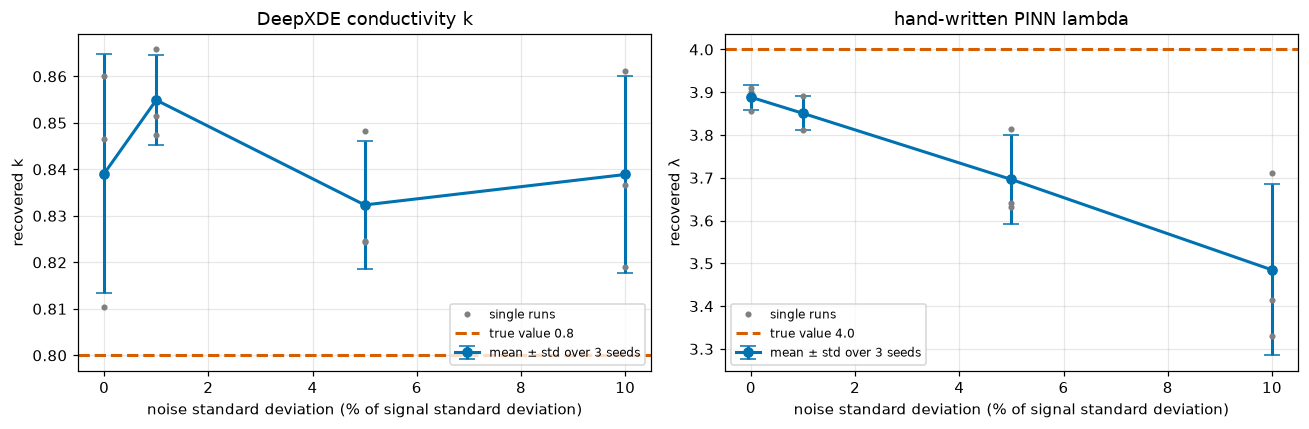

Result (B): DeepXDE conductivity k, noise 0 %: 0.8391 ± 0.0257 (error 4.9 ± 3.2 %); DeepXDE conductivity k, noise 1 %: 0.8549 ± 0.0097 (error 6.9 ± 1.2 %); DeepXDE conductivity k, noise 5 %: 0.8323 ± 0.0137 (error 4.0 ± 1.7 %); DeepXDE conductivity k, noise 10 %: 0.8389 ± 0.0212 (error 4.9 ± 2.7 %); hand-written PINN lambda, noise 0 %: 3.8884 ± 0.0290 (error 2.8 ± 0.7 %); hand-written PINN lambda, noise 1 %: 3.8507 ± 0.0399 (error 3.7 ± 1.0 %); hand-written PINN lambda, noise 5 %: 3.6962 ± 0.1031 (error 7.6 ± 2.6 %); hand-written PINN lambda, noise 10 %: 3.4848 ± 0.1997 (error 12.9 ± 5.0 %)


In [8]:
runs_b = pd.concat([runs_k, runs_l], ignore_index=True); runs_b.to_csv(RES / "b_noise_runs.csv", index=False)
g = runs_b.groupby(["method", "noise_frac"], sort=False).agg(value_mean=("value", "mean"), value_std=("value", "std"), rel_err_mean=("rel_err_pct", "mean"), rel_err_std=("rel_err_pct", "std"), true=("true", "first")).reset_index()
table = g.pivot(index="noise_frac", columns="method", values=["value_mean", "value_std", "rel_err_mean", "rel_err_std"])
table.columns = [f"{m}: {v}" for v, m in table.columns]; table = table.reset_index().rename(columns={"noise_frac": "noise (fraction of signal std)"})
table.to_csv(RES / "b_noise_summary.csv", index=False); print(table.round(4).to_string(index=False))
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, (meth, true, lab) in zip(axs, (("DeepXDE conductivity k", k_true, "recovered k"), ("hand-written PINN lambda", 4.0, "recovered λ"))):
    r = g[g.method == meth]; ax.errorbar([f * 100 for f in r.noise_frac], r.value_mean, yerr=r.value_std, fmt="o-", color=CB[0], capsize=5, lw=2, label="mean ± std over 3 seeds")
    rr = runs_b[runs_b.method == meth]; ax.plot(rr.noise_frac * 100, rr.value, ".", color="0.5", ms=6, label="single runs")
    ax.axhline(true, color=CB[3], ls="--", lw=2, label=f"true value {true}"); ax.set_xlabel("noise standard deviation (% of signal standard deviation)"); ax.set_ylabel(lab); ax.set_title(meth); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(RES / "b_noise_robustness.png", dpi=110); plt.show()
print("Result (B): " + "; ".join(f"{r.method}, noise {r.noise_frac*100:.0f} %: {r.value_mean:.4f} ± {r.value_std:.4f} (error {r.rel_err_mean:.1f} ± {r.rel_err_std:.1f} %)" for _, r in g.iterrows()))

## Files
In `../results/05_data_efficiency_and_noise/`: `a_data_efficiency_runs.csv`, `a_data_efficiency_summary.csv`, `a_data_efficiency.png`; `b_noise_deepxde_runs.csv`, `b_noise_handwritten_runs.csv`, `b_noise_runs.csv`, `b_noise_summary.csv` (one table, both methods), `b_noise_robustness.png`. The DeepONet models of part A are in `../models/05_data_efficiency_and_noise/`.